In [85]:
import numpy as np
from numpy import sqrt, pi, log, exp, linspace, diff, zeros
from numpy.linalg import eig, eigvals, det
import matplotlib.pyplot as plt
from scipy.ndimage import minimum_filter

## This notebook aims to reproduce **Figure 1** of the following paper: [Brillouin-Wigner perturbation theory in open electromagnetic systems](https://iopscience.iop.org/article/10.1209/0295-5075/92/50010/pdf?casa_token=EI3v9y-qFNIAAAAA:tBj4r5au-336TDXGIbSpMH7XzEq2BcKeGIWVERgDlgFolgZuS3j3F7-WwU2ekV6E6NDKbXSjo5BFJGvmcHll5lOPHT0). **Figure 1** shows the resonance frequencies corresponding to a perturbation in a slab, calculated directly and calculated through non-Hermitian perturbation theory.

In [137]:
def find_local_minima(arr, neighborhood_len=3):
    neighborhood = np.ones((neighborhood_len, neighborhood_len), dtype=bool)
    local_min_mask = (minimum_filter(arr, footprint=neighborhood, mode='constant', cval=np.inf) == arr)
    coordinates = np.argwhere(local_min_mask)    
    return coordinates

In [2]:
def slab_resonance(m, n): # m indexes the mode index, n is the index of refraction
    return (pi/(2*n))*(m)-(1j/(2*n))*log((n+1)/(n-1)) # k_m*a
def mode_profile(m, n, k_m, z): # z is the normalized coordinate (in units of a)
    B_m = (-1j)**m/(2*n)
    return B_m*(exp(1j*n*k_m*z) + ((-1)**m)*exp(-1j*n*k_m*z))
def v_mn(delta_epsilon, z_v, mode_1, mode_2):
    delta_z = diff(z_v)[0]
    return (mode_1 * mode_2 * delta_epsilon * delta_z).sum()

### The function $V_{mn}$ above is defined by **Equation 16** of the paper. The function `mode_profile` is given by **Equation 3** with the normalization given by **Equation 6** (note that `mode_profile` only gives the profile of the mode for $-a<z<a$, since we only need it in that range. Finally, the function `slab_resonance` is given by **Equation 4** of the paper. We start, in the cell below, by verifying the orthogonality relation given by **Equation 5** of the paper.

In [18]:
m_max = 10 # Maximum mode index considered 
n_z = 100000 # Number of real space points sampled within the slab
z_v = linspace(-1, 1, n_z) # Range of z in normalized units (normalized by a)
epsilon = 2.25
overlaps_v_v = []
for m_1 in range(-m_max, m_max+1):
    k_m_1 = slab_resonance(m_1, sqrt(epsilon))
    mode_1 = mode_profile(m_1, sqrt(epsilon), k_m_1, z_v)
    overlaps_v = []
    for m_2 in range(-m_max, m_max+1):
        k_m_2 = slab_resonance(m_2, sqrt(epsilon))
        mode_2 = mode_profile(m_2, sqrt(epsilon), k_m_2, z_v)
        surface_term = (mode_1[0]*mode_2[0] + mode_1[-1]*mode_2[-1])/(1j*(k_m_1 + k_m_2))
        integral_term = epsilon*(mode_1 * mode_2).sum()*diff(z_v)[0]
        overlap = (integral_term -  surface_term).round(4)
        assert np.abs(overlap.imag) < 1e-6
        overlaps_v.append(overlap.real)
    overlaps_v_v.append(overlaps_v)

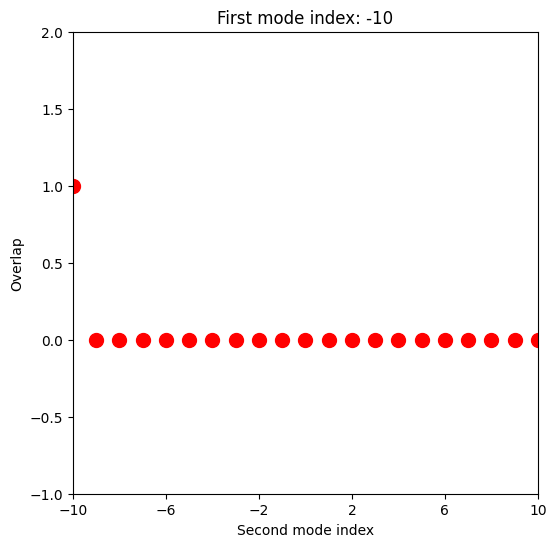

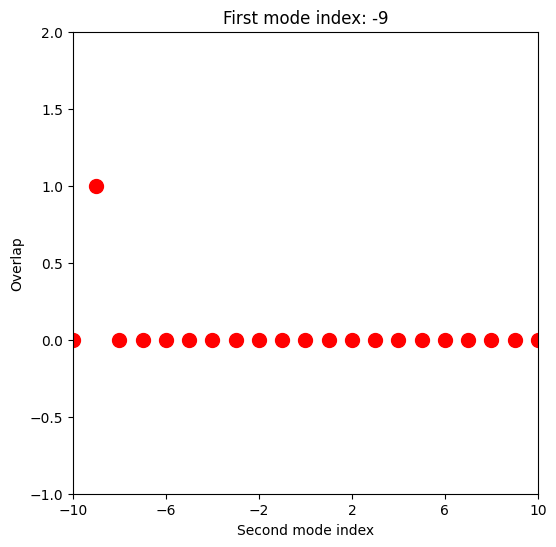

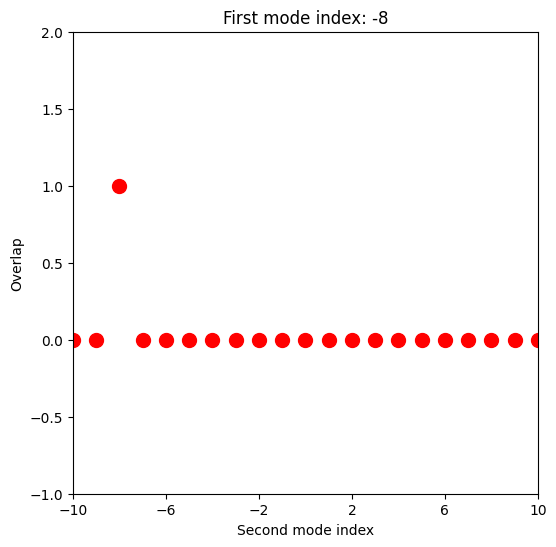

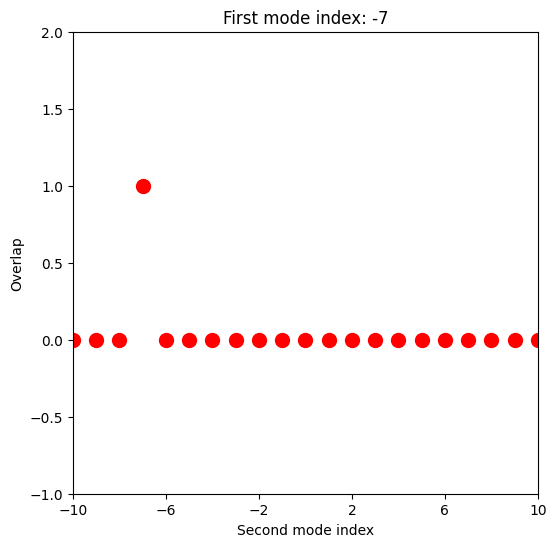

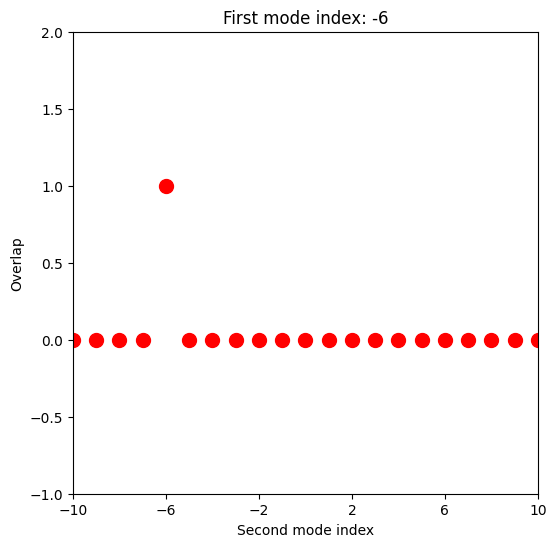

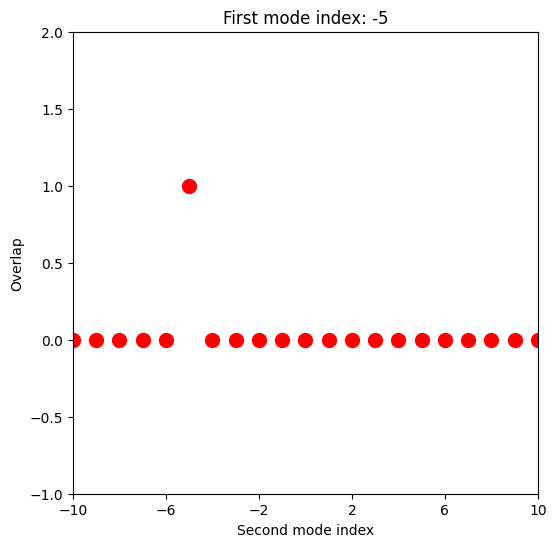

In [39]:
s=100
plt.close('all')
for (m_idx, m) in enumerate(range(-m_max, m_max+1)):
    if (m_idx > 5):
        continue
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(range(-m_max, m_max+1), overlaps_v_v[m_idx], color="red", s=s)
    ax.set_xlim(-10, 10)
    ax.set_ylim(-1, 2)
    ax.set_title(f"First mode index: {m}")
    ax.set_xlabel("Second mode index")
    ax.set_ylabel("Overlap")
    ax.set_xticks(range(-m_max, m_max+1, 4))

In [110]:
delta_epsilon = 100
n_z = 100000
epsilon = 2.25
perturbation_z_v = linspace(1/2, 1, n_z)
max_m = 200
hamiltonian_matrix = zeros((2*max_m+1, 2*max_m+1), dtype=complex)

for (m_1_idx, m_1) in enumerate(range(-max_m, max_m+1)):
    if (m_1_idx % 20 == 0):
        print(f"m_1 = {m_1}")
    k_m_1 = slab_resonance(m_1, sqrt(epsilon))
    mode_1 = mode_profile(m_1, sqrt(epsilon), k_m_1, perturbation_z_v)
    hamiltonian_matrix[m_1_idx, m_1_idx] += 1/k_m_1

    for (m_2_idx, m_2) in enumerate(range(-max_m, max_m+1)):
        k_m_2 = slab_resonance(m_2, sqrt(epsilon))
        mode_2 = mode_profile(m_2, sqrt(epsilon), k_m_2, perturbation_z_v)
        off_diagonal_normalization = 2*sqrt(k_m_1*k_m_2)
        if off_diagonal_normalization.imag > 0: 
            off_diagonal_normalization = -off_diagonal_normalization
        hamiltonian_matrix[m_1_idx, m_2_idx] += v_mn(delta_epsilon, perturbation_z_v, mode_1, mode_2)/off_diagonal_normalization

m_1 = -200
m_1 = -180
m_1 = -160
m_1 = -140
m_1 = -120
m_1 = -100
m_1 = -80
m_1 = -60
m_1 = -40
m_1 = -20
m_1 = 0
m_1 = 20
m_1 = 40
m_1 = 60
m_1 = 80
m_1 = 100
m_1 = 120
m_1 = 140
m_1 = 160
m_1 = 180
m_1 = 200


In [112]:
#qnm_inv_frequencies, qnm_profiles = eig(hamiltonian_matrix)
qnm_inv_frequencies_perturbation = eigvals(hamiltonian_matrix)
qnm_frequencies_perturbation = 1/qnm_inv_frequencies_perturbation
qnm_frequencies_real_perturbation = qnm_frequencies_perturbation.real
qnm_frequencies_imag_perturbation = qnm_frequencies_perturbation.imag

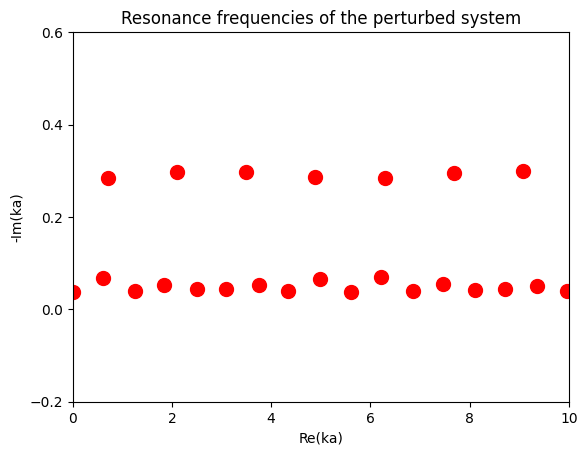

In [114]:
s=100
plt.scatter(qnm_frequencies_real_perturbation, -qnm_frequencies_imag_perturbation, s=s, color="red")
plt.xlim(0, 10)
#plt.ylim(0, 1)
plt.ylim(-0.2, 0.6);
plt.yticks([-0.2, 0, 0.2, 0.4, 0.6]);
plt.title("Resonance frequencies of the perturbed system");
plt.xlabel("Re(ka)")
plt.ylabel("-Im(ka)");

### We now find the exact resonance frequencies of the perturbed slab by setting up a matrix equation. For $x<-a$, we take the field to be given by $A_0 e^{-ik x}$. For $-a<z<a/2$, we take the field to be given by $A_1 e^{-in_1kx}+A_2 e^{in_1k x}$, where $n_1$ is the index of refraction in that region. Thus, we must have $A_0 e^{ika}=A_1e^{in_1ka}+A_2 e^{-in_1ka}$ as well as $-A_0 e^{ika}=-n_1A_1e^{in_1ka}+n_1A_2 e^{-in_1ka}$. For $a/2<x<a$, we have $A_3 e^{-in_2x}+A_4 e^{in_2 x}$, which gives us the two relations $A_1 e^{-in_1ka/2}+A_2 e^{in_1ka/2}=A_3 e^{-in_2ka/2}+A_4e^{in_2ka/2}$ and $-n_1A_1 e^{-in_1ka/2}+ n_1A_2 e^{in_1ka/2}=-n_2A_3 e^{-in_2ka/2}+n_2A_4e^{in_2ka/2}$. Finally, for $x>a$, we have $A_5 e^{ikx}$, which gives us the two relations $A_3e^{-in_2 k a}+A_4 e^{in_2 ka}=A_5e^{ika}$ and $-n_2A_3e^{-in_2 k a}+n_2A_4 e^{in_2 ka}=A_5e^{ika}$

In [116]:
def perturbed_slab_resonance(k, epsilon, delta_epsilon): # k is non-dimensionalized. I.e. it is really ka
    n_1 = sqrt(epsilon)
    n_2 = sqrt(epsilon + delta_epsilon)
    hamiltonian = zeros((6, 6), dtype=complex)
    hamiltonian[0, 0] = -exp(1j*k); 
    hamiltonian[0, 1] = exp(1j*n_1*k); 
    hamiltonian[0, 2] = exp(-1j*n_1*k);
    
    hamiltonian[1, 0] = exp(1j*k); 
    hamiltonian[1, 1] = -n_1*exp(1j*n_1*k); 
    hamiltonian[1, 2] = n_1*exp(-1j*n_1*k);

    hamiltonian[2, 1] = -exp(-1j*n_1*k/2)
    hamiltonian[2, 2] = -exp(1j*n_1*k/2)
    hamiltonian[2, 3] = exp(-1j*n_2*k/2)
    hamiltonian[2, 4] = exp(1j*n_2*k/2) 

    hamiltonian[3, 1] = n_1*exp(-1j*n_1*k/2)
    hamiltonian[3, 2] = -n_1*exp(1j*n_1*k/2)
    hamiltonian[3, 3] = -n_2*exp(-1j*n_2*k/2)
    hamiltonian[3, 4] = n_2*exp(1j*n_2*k/2)

    hamiltonian[4, 3] = exp(-1j*n_2*k)
    hamiltonian[4, 4] = exp(1j*n_2*k)
    hamiltonian[4, 5] = -exp(1j*k)

    hamiltonian[5, 3] = -n_2*exp(-1j*n_2*k)
    hamiltonian[5, 4] = n_2*exp(1j*n_2*k)
    hamiltonian[5, 5] = -exp(1j*k)
    return det(hamiltonian)

In [138]:
n_k_real = 1000
n_k_imag = 1000
k_real_v = linspace(0, 10, n_k_real)
k_imag_v = linspace(0, 0.4, n_k_imag)

epsilon = 2.25
delta_epsilon = 100
mode_condition_arr = zeros((n_k_real, n_k_imag), dtype=complex)
for (k_real_idx, k_real) in enumerate(k_real_v):
    for (k_imag_idx, k_imag) in enumerate(k_imag_v):
        mode_condition_arr[k_real_idx, k_imag_idx] = perturbed_slab_resonance(k_real-1j*k_imag, epsilon, delta_epsilon)

mode_heatmap_data = log(np.abs(mode_condition_arr))
argmin_data = find_local_minima(mode_heatmap_data)
mode_k_real = argmin_data[:, 0]
mode_k_imag = argmin_data[:, 1]
qnm_frequencies_real_exact = k_real_v[mode_k_real]
qnm_frequencies_imag_exact = k_imag_v[mode_k_imag]

### Below is Figure 1 of the Muljarov paper

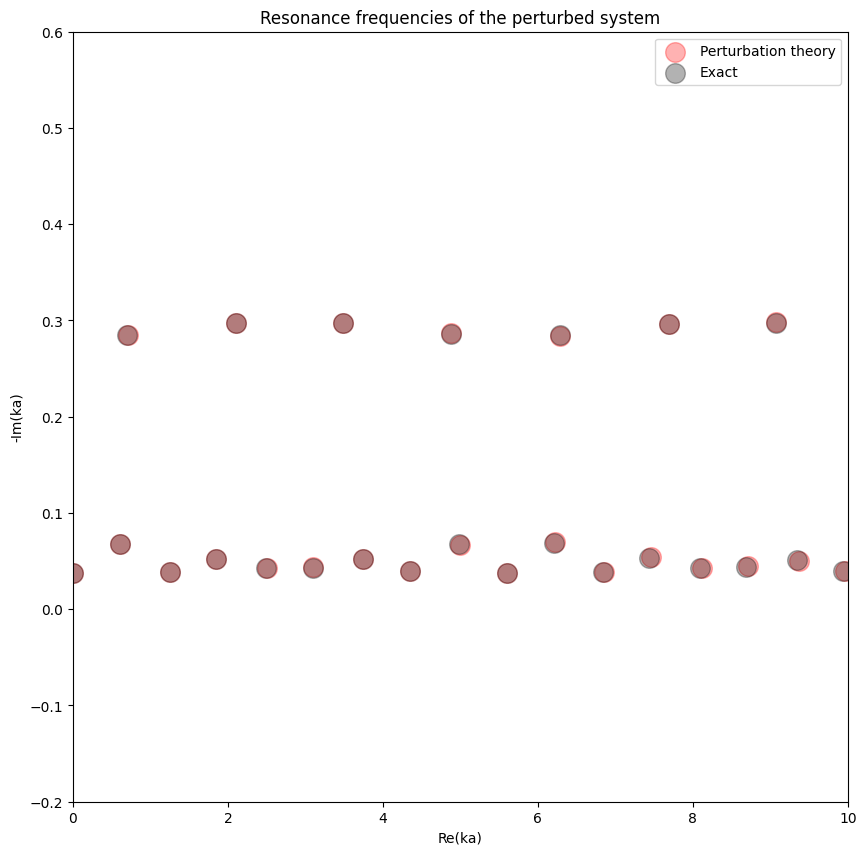

In [139]:
s = 200
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(qnm_frequencies_real_perturbation, -qnm_frequencies_imag_perturbation, s=s, color="red", alpha=0.3, label="Perturbation theory")
ax.scatter(qnm_frequencies_real_exact, qnm_frequencies_imag_exact, s=s, color="black", alpha=0.3, label="Exact")

ax.set_ylim(-0.2, 0.6)
ax.set_xlim(0, 10);
ax.legend()

ax.set_title("Resonance frequencies of the perturbed system");
ax.set_xlabel("Re(ka)")
ax.set_ylabel("-Im(ka)");